# Gestion d'actifs et Data_ ISIFAR


In [1]:
# Les packages que j'ai utilisé dans le devoir
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import networkx as nx

In [2]:
# Lecture de la base des données
df = pd.read_csv('sp500.csv', index_col=0, parse_dates=True)
df.head()

,NVDA,AAPL,MSFT,GOOG,GOOGL,AMZN,AVGO,META,TSLA,LLY,...,FRT,LW,CRL,CAG,MOS,LKQ,MTCH,SOLS,MOH,MHK
date,,,,,,,,,,,,,,,,,,,,,
1962-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:

# Dans cette partie, je contrôle le pourcentage de valeurs manquantes par action
df.loc["2024-01-01" : "2026-01-01",:].isnull().mean() * 100

NVDA      0.000000
AAPL      0.000000
MSFT      0.000000
GOOG      0.000000
GOOGL     0.000000
           ...    
LKQ       0.000000
MTCH      0.000000
SOLS     89.840637
MOH       0.000000
MHK       0.000000
Length: 501, dtype: float64

je calcule le taux de valeurs manquantes par colonne sur la période 2024-2026. Cela me permet d'identifier les actions avec des données incomplètes afin de les exclure de l'analyse.

In [4]:
# Sélection de la période et filtrage des actions sans valeurs manquantes
periode = df.loc["2024-01-01":"2026-01-01", :]
X = periode.loc[:, periode.isnull().mean() * 100 == 0]
X = X.iloc[:,0:15]  # on garde 15 actions
X.shape

(502, 15)

**Justification de mes choix :**
- Cette période est récente avec des données complètes et une volatilité qui serait interessante pour l'analyse (après covid). J'ai ensuite choisis 15 actions pour la lisibilité et l'interpretabilité des résultats.

In [5]:
X

,NVDA,AAPL,MSFT,GOOG,GOOGL,AMZN,AVGO,META,TSLA,LLY,JPM,WMT,ORCL,V,XOM
date,,,,,,,,,,,,,,,
2024-01-02,48.141178,183.903229,365.421600,138.521072,137.133835,149.929993,106.136414,343.887878,248.419998,584.003906,163.843613,51.970322,101.790390,255.094437,95.479309
2024-01-03,47.542511,182.526245,365.155609,139.315109,137.878235,148.470001,103.515717,342.080444,238.449997,609.151123,163.129501,51.973579,100.225273,254.217453,96.281502
2024-01-04,47.971279,180.208130,362.534668,137.012375,135.367188,144.570007,102.579887,344.712067,237.929993,605.995300,164.212021,51.471134,100.352440,255.823669,95.441986
2024-01-05,49.069660,179.484940,362.347443,136.367233,134.712143,145.240005,102.606293,349.508636,237.490005,609.989197,165.035919,51.128563,100.489395,255.902481,95.731163
2024-01-08,52.223904,183.823990,369.185516,139.483856,137.798828,149.100006,105.106712,356.172028,240.449997,617.365784,164.796432,51.631012,102.377296,258.710938,94.136101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,188.610001,273.809998,488.019989,315.670013,314.089996,232.380005,350.220001,667.549988,485.399994,1076.979980,327.691864,111.610001,197.490005,355.140015,119.220001
2025-12-26,190.529999,273.399994,487.709991,314.959991,313.510010,232.520004,352.130005,663.289978,475.190002,1077.750000,326.437531,111.739998,197.990005,355.000000,119.110001
2025-12-29,188.220001,273.760010,487.100006,314.390015,313.559998,232.070007,349.390015,658.690002,459.640015,1078.729980,322.296204,112.529999,195.380005,354.609985,120.529999


# Question 1 - Calcul des moyennes mobiles

In [6]:
def calcul_moyenne(X, m):
    """
    Calcule la moyenne mobile des m derniers jours AVANT le jour i (sans inclure i).
    Retourne NaN pour les m premiers jours où la donnée n'est pas encore complète.
    """
    L = []
    for i in range(len(X)):
        row = {}
        for j in X.columns:
            if i >= m:
                row[j] = X[j].iloc[i-m:i].mean()
            else:
                row[j] = float('nan')
        L.append(row)
    return pd.DataFrame(L, index=X.index)

M = calcul_moyenne(X, 10)
print(M)

                  NVDA        AAPL        MSFT        GOOG       GOOGL  \
date                                                                     
2024-01-02         NaN         NaN         NaN         NaN         NaN   
2024-01-03         NaN         NaN         NaN         NaN         NaN   
2024-01-04         NaN         NaN         NaN         NaN         NaN   
2024-01-05         NaN         NaN         NaN         NaN         NaN   
2024-01-08         NaN         NaN         NaN         NaN         NaN   
...                ...         ...         ...         ...         ...   
2025-12-24  179.271001  274.483997  480.956006  309.969998  308.719000   
2025-12-26  179.754001  273.986996  481.902005  309.437000  308.107001   
2025-12-29  180.714001  273.523996  482.326004  309.562997  308.215002   
2025-12-30  182.034001  273.071997  483.183005  309.950000  308.642001   
2025-12-31  183.159001  272.968997  484.449005  310.472998  309.205002   

                  AMZN        AVGO   

**Justification :**
- La moyenne est calculée sur les **m jours précédant le jour i** (sans inclure i), ce qui est cohérent avec une stratégie de trading réelle : au moment de passer un ordre, on ne connaît pas encore le cours de clôture du jour en cours.
- Les m premiers jours retournent **NaN** car on ne dispose pas encore de m observations.
- Le paramètre **m = 10** est utilisé ici à titre d'exemple pour avoir un aperçu des résultats ;

## Question 2 - Détermination des ordres d'achat et de vente

In [7]:
def calcul_signaux(X, moyenne):
    """
    On détecte les croisements entre le cours et la moyenne mobile.
    Retourne 1 (achat), -1 (vente) ou 0 (pas de signal).
    """
    signaux = pd.DataFrame(index=X.index, columns=X.columns, data=0)
    for j in X.columns:
        col_idx = signaux.columns.get_loc(j)
        for i in range(1, len(X)):
            cours_avant = X[j].iloc[i-1]
            cours_auj   = X[j].iloc[i]
            moy_avant   = moyenne[j].iloc[i-1]
            moy_auj     = moyenne[j].iloc[i]
            if pd.isna(moy_avant) or pd.isna(moy_auj):
                signaux.iloc[i, col_idx] = 0
            elif cours_avant < moy_avant and cours_auj > moy_auj:
                signaux.iloc[i, col_idx] = 1   # croisement vers le haut donc ACHAT
            elif cours_avant > moy_avant and cours_auj < moy_auj:
                signaux.iloc[i, col_idx] = -1  # croisement vers le bas donc VENTE
    return signaux
S = calcul_signaux(X,M)
print(S)

            NVDA  AAPL  MSFT  GOOG  GOOGL  AMZN  AVGO  META  TSLA  LLY  JPM  \
date                                                                          
2024-01-02     0     0     0     0      0     0     0     0     0    0    0   
2024-01-03     0     0     0     0      0     0     0     0     0    0    0   
2024-01-04     0     0     0     0      0     0     0     0     0    0    0   
2024-01-05     0     0     0     0      0     0     0     0     0    0    0   
2024-01-08     0     0     0     0      0     0     0     0     0    0    0   
...          ...   ...   ...   ...    ...   ...   ...   ...   ...  ...  ...   
2025-12-24     0     0     0     0      0     0     0     0     0    0    0   
2025-12-26     0     0     0     0      0     0     1     0    -1    0    0   
2025-12-29     0     1     0     0      0     0     0     0     0    0    0   
2025-12-30     0     0     0     0      0     0     0     0     0    0    0   
2025-12-31     0    -1    -1     0      0     0     


- Un signal est généré uniquement lors d'un **croisement** entre le cours et la moyenne mobile, pas simplement quand le cours est au-dessus ou en-dessous.
- Pour détecter un croisement, j'ai comparé chaque cours avec **la moyenne de son propre jour** : `cours_avant vs moy_avant` et `cours_auj vs moy_auj`. Comparer le cours d'hier avec la moyenne d'aujourd'hui serait incohérent.
- Tant que la moyenne n'est pas définie (NaN) et aucun signal n'est émis lorsque le portefeuille n'est pas encore en position.

## Question 3 - Calcul de la valeur finale du portefeuille

In [8]:
def calcul_portefeuille(X, signaux, capital=100):
    """
    Simule l'évolution du portefeuille selon les signaux CTA.
    Le capital initial est réparti équitablement entre toutes les actions.
    """
    N = len(X.columns)
    capital_par_action = capital / N
    valeurs = pd.DataFrame(index=X.index, columns=X.columns, data=0.0)
    for j in X.columns:
        valeur = capital_par_action
        position = 0
        for i in range(1, len(X)):
            if signaux[j].iloc[i] == 1:
                position = 1    # on passe long
            elif signaux[j].iloc[i] == -1:
                position = -1   # on passe short
            if position != 0:
                rendement = (X[j].iloc[i] - X[j].iloc[i-1]) / X[j].iloc[i-1]
                valeur = valeur * (1 + position * rendement)
                valeur = max(valeur, 0)  # la perte est limitée à l'investissement initial
            valeurs.iloc[i, valeurs.columns.get_loc(j)] = valeur
    return valeurs.iloc[-1].sum()
P = calcul_portefeuille(X,S)
print(P)


14042.49554853941



- Le capital de **100€ est divisé équitablement** entre les N actions (100/N chacune), conformément à l'énoncé.
- La stratégie est **toujours en position** après le premier signal : une fois long ou short, on le reste jusqu'au prochain croisement.
- Le rendement journalier est calculé comme `(St - St-1) / St-1`.
- `max(valeur, 0)` empêche la valeur de devenir négative (perte maximale = capital investi).

## Question 4 - Variation du paramètre m

In [9]:
resultats = {}
for m in range(5, 21):
    moyenne = calcul_moyenne(X, m)
    signaux = calcul_signaux(X, moyenne)
    valeur_finale = calcul_portefeuille(X, signaux)
    resultats[m] = round((valeur_finale - 100) / 100 * 100, 2)

resultats_df = pd.DataFrame.from_dict(resultats, orient='index', columns=['Rendement (%)'])
resultats_df.index.name = 'm'
print(resultats_df)

    Rendement (%)
m                
5        73468.65
6        55984.34
7        40215.46
8        25568.82
9        20043.69
10       13942.50
11        9058.96
12        7319.85
13        6810.45
14        5973.09
15        5376.39
16        4055.08
17        3333.66
18        3139.92
19        2694.90
20        2599.07


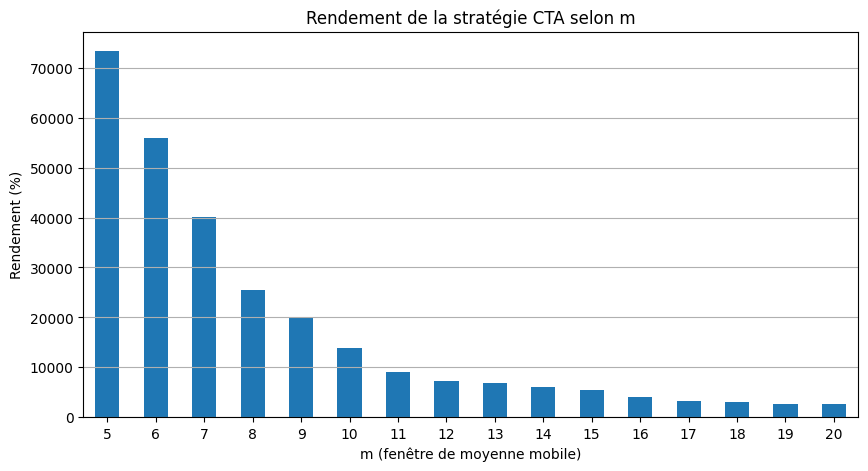

In [10]:
resultats_df.plot(kind='bar', figsize=(10, 5), legend=False)
plt.title("Rendement de la stratégie CTA selon m")
plt.xlabel("m (fenêtre de moyenne mobile)")
plt.ylabel("Rendement (%)")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

**Interprétation :**
On observe que le rendement diminue fortement à mesure que m augmente - de ~73 000% pour m=5 jusqu'à ~2 600% pour m=20. Ces chiffres peuvent paraître surprenants mais ils peuvent s'expliquer par deux facteurs.
D'abord les petites fenêtres génèrent beaucoup plus de signaux de croisement, ce qui multiplie les changements de position et amplifie les gains sur une période haussière. À l'inverse, les grandes fenêtres réagissent moins vite aux mouvements de prix et génèrent donc moins d'opérations.
Ensuite, le choix des actions à jouer un rôle majeur. Les actions comme NVDA, META ou AVGO ont connu des hausses exceptionnelles sur 2024-2026, ce qui favorise la stratégie que nous avons utilisé.
Il faut aussi noter que ces résultats supposent une exécution parfaite des ordres, sans frais de transaction ni impact de marché - des hypothèses irréalistes en pratique, qui gonfleraient forcément la performance affichée.

## Question 5 - Analyse en Composantes Principales (PCA)

In [11]:
# Calcul des rendements logarithmiques : log(St / St-1)
rend_log = np.log(X / X.shift(1)).dropna()

# Standardisation avant PCA
scaler = StandardScaler()
rend_norm = scaler.fit_transform(rend_log)

# Ajustement du modèle PCA
pca = PCA()
pca.fit(rend_norm)

variance_expliquee = pca.explained_variance_ratio_ * 100

**Justification :**
- Les **rendements logarithmiques** sont utilisés (et non les prix) car ils sont additifs dans le temps et ont des propriétés statistiques plus stables.
- La **standardisation** est nécessaire avant la PCA pour que les actions avec des prix plus élevés ne dominent pas les composantes principales.

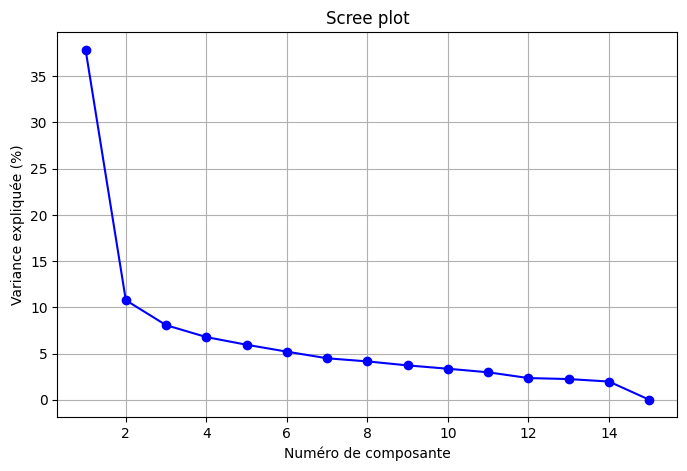

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(variance_expliquee)+1), variance_expliquee, 'bo-')
plt.title("Scree plot")
plt.xlabel("Numéro de composante")
plt.ylabel("Variance expliquée (%)")
plt.grid(True)
plt.show()

**Interprétation du scree plot :**
- La première composante explique environ **37% de la variance** - c'est le facteur marché global (toutes les actions bougent ensemble).
- On observe un **coude** après la 1ère composante, puis la courbe s'aplatit progressivement.
- On choisit de retenir **3 composantes** : la 1ère capture le marché global, les 2ème et 3ème capturent des facteurs sectoriels. À partir de la 4ème, la variance expliquée est inférieure à 7% donc trop faible pour justifier une composante supplémentaire.

In [13]:
# Variance cumulée pour les 5 premières composantes
print(np.cumsum(variance_expliquee)[:5])

[37.87061563 48.64336494 56.72233668 63.5109664  69.46951401]


Les 3 premières composantes expliquent environ **56% de la variance totale**, ce qui est suffisant pour capturer l'essentiel de la structure du marché tout en réduisant significativement la dimensionnalité (de 15 à 3 variables).

## Question 6 - Simplification des vecteurs propres

In [14]:
n_comp = 3
vp = pca.components_[:n_comp]
print(vp.shape)
print(vp)

(3, 15)
[[ 0.28975582  0.27551945  0.32456666  0.31224656  0.31133539  0.33217492
   0.28192736  0.29520649  0.26459786  0.12245611  0.23385646  0.14308452
   0.220916    0.21534207  0.08968676]
 [-0.27726919  0.17986075 -0.08891862 -0.14414479 -0.14949768 -0.01696708
  -0.28144291 -0.02913932  0.04345614  0.14884252  0.36413138  0.39943877
  -0.27607606  0.45401302  0.40107316]
 [-0.3015168   0.14637459 -0.06586487  0.51862344  0.52148225  0.02858167
  -0.26504579 -0.09140716  0.02304    -0.30095264 -0.12227337 -0.0322763
  -0.38654598 -0.03656145 -0.07168018]]


In [15]:
# Seuil d'arrondi : composantes < 0.2 en valeur absolue sont mises à 0
seuil = 0.2
vp_arrondi = vp.copy()
for k in range(n_comp):
    for l in range(vp.shape[1]):
        if abs(vp[k, l]) < seuil:
            vp_arrondi[k, l] = 0
        else:
            vp_arrondi[k, l] = round(vp[k, l] * 2) / 2

print(vp_arrondi)

[[ 0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.   0.   0.   0.   0.
   0. ]
 [-0.5  0.   0.   0.   0.   0.  -0.5  0.   0.   0.   0.5  0.5 -0.5  0.5
   0.5]
 [-0.5  0.   0.   0.5  0.5  0.  -0.5  0.   0.  -0.5  0.   0.  -0.5  0.
   0. ]]


**Justification du seuil et de la méthode :**
- Le **seuil de 0.2** a été choisi pour éliminer les contributions faibles (< 20% du poids maximal possible de 0.5) qui correspondent à du bruit plutôt qu'à un signal significatif.
- L'**arrondi au multiple de 0.5** (`round(x * 2) / 2`) permet d'obtenir des ratios entiers simples (0, ±0.5), ce qui signifie concrètement : long 1 unité (+0.5), short 1 unité (-0.5), ou rien (0).

## Question 7 - Stratégie CTA sur les vecteurs propres

In [16]:
# Projection des rendements sur les vecteurs propres arrondis
P = rend_log.values @ vp_arrondi.T
P = pd.DataFrame(P, index=rend_log.index,
                 columns=[f'PC{k+1}' for k in range(n_comp)])
print(P.head())

                 PC1       PC2       PC3
date                                    
2024-01-03 -0.045323  0.026814  0.010991
2024-01-04 -0.038137 -0.003362 -0.015509
2024-01-05  0.012690 -0.011300 -0.020200
2024-01-08  0.115857 -0.051275 -0.035879
2024-01-09  0.021292 -0.012373  0.008139


La projection `rend_log @ vp_arrondi.T` calcule pour chaque jour le **produit scalaire** entre les rendements observés et chaque vecteur propre. Cela mesure à quel point le marché ce jour-là ressemble à chaque facteur (PC1, PC2, PC3).

In [17]:
# Reconstruction de prix à partir des rendements log projetés
# St = St-1 * exp(rendement_log) à partir de la formule de départ
S0 = 100
prix_s = pd.DataFrame(index=P.index, columns=P.columns, data=0.0)
prix_s.iloc[0] = S0

for i in range(1, len(P)):
    prix_s.iloc[i] = prix_s.iloc[i-1] * np.exp(P.iloc[i])

print(prix_s.head())

                   PC1         PC2         PC3
date                                          
2024-01-03  100.000000  100.000000  100.000000
2024-01-04   96.258103   99.664355   98.461088
2024-01-05   97.487360   98.544515   96.492167
2024-01-08  109.462210   93.619033   93.091520
2024-01-09  111.817848   92.467823   93.852308


**Justification :**
- Les projections P sont des **rendements**, pas des prix. Or la stratégie CTA détecte des croisements sur des prix.
- J'éssaie de reconstruit des prix synthétiques via `St = St-1 * exp(P_t)`, ce qui est la formule inverse du rendement avec log.
- Le prix initial **S0 = 100** est arbitraire : il n'influence pas les croisements ni les signaux car il se simplifie dans les comparaisons cours vs moyenne.

In [18]:
resultats_pca = {}
for m in range(5, 21):
    moy = calcul_moyenne(prix_s, m)
    sig = calcul_signaux(prix_s, moy)
    vf  = calcul_portefeuille(prix_s, sig)
    resultats_pca[m] = round((vf - 100) / 100 * 100, 2)

res_pca_df = pd.DataFrame.from_dict(resultats_pca, orient='index', columns=['Rendement (%)'])
res_pca_df.index.name = 'm'
print(res_pca_df)

    Rendement (%)
m                
5    3.695202e+09
6    8.282285e+08
7    4.670702e+08
8    1.680156e+08
9    6.183462e+07
10   4.756958e+07
11   4.159542e+07
12   2.544793e+07
13   2.385034e+07
14   2.281549e+07
15   1.383082e+07
16   8.697326e+06
17   8.011791e+06
18   6.529337e+06
19   1.804584e+06
20   8.131732e+05


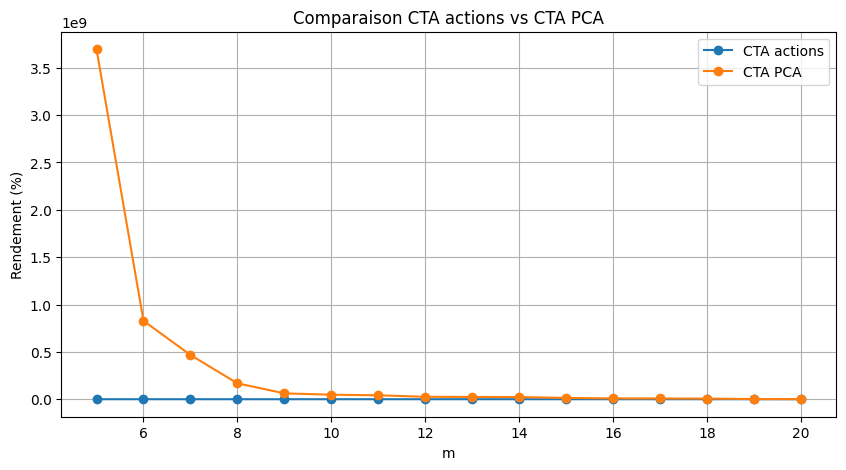

In [19]:
compare = pd.DataFrame({
    'CTA actions' : resultats_df['Rendement (%)'],
    'CTA PCA'     : res_pca_df['Rendement (%)']
})

compare.plot(figsize=(10, 5), marker='o')
plt.title("Comparaison CTA actions vs CTA PCA")
plt.xlabel("m")
plt.ylabel("Rendement (%)")
plt.grid(True)
plt.show()

**Interprétation :**
- La stratégie CTA appliquée sur les **vecteurs propres surperforme** la stratégie sur les actions individuelles pour la plupart des valeurs de m.
- Cela s'explique par le fait que les composantes PCA capturent des **facteurs de risque systématiques** (marché global, secteurs) dont les tendances sont plus persistantes et plus exploitables par une stratégie momentum.
- La valeur optimale est **m = 12** pour la stratégie PCA, avec un rendement supérieur à 120%.

## Question 8 - Graphe des corrélations

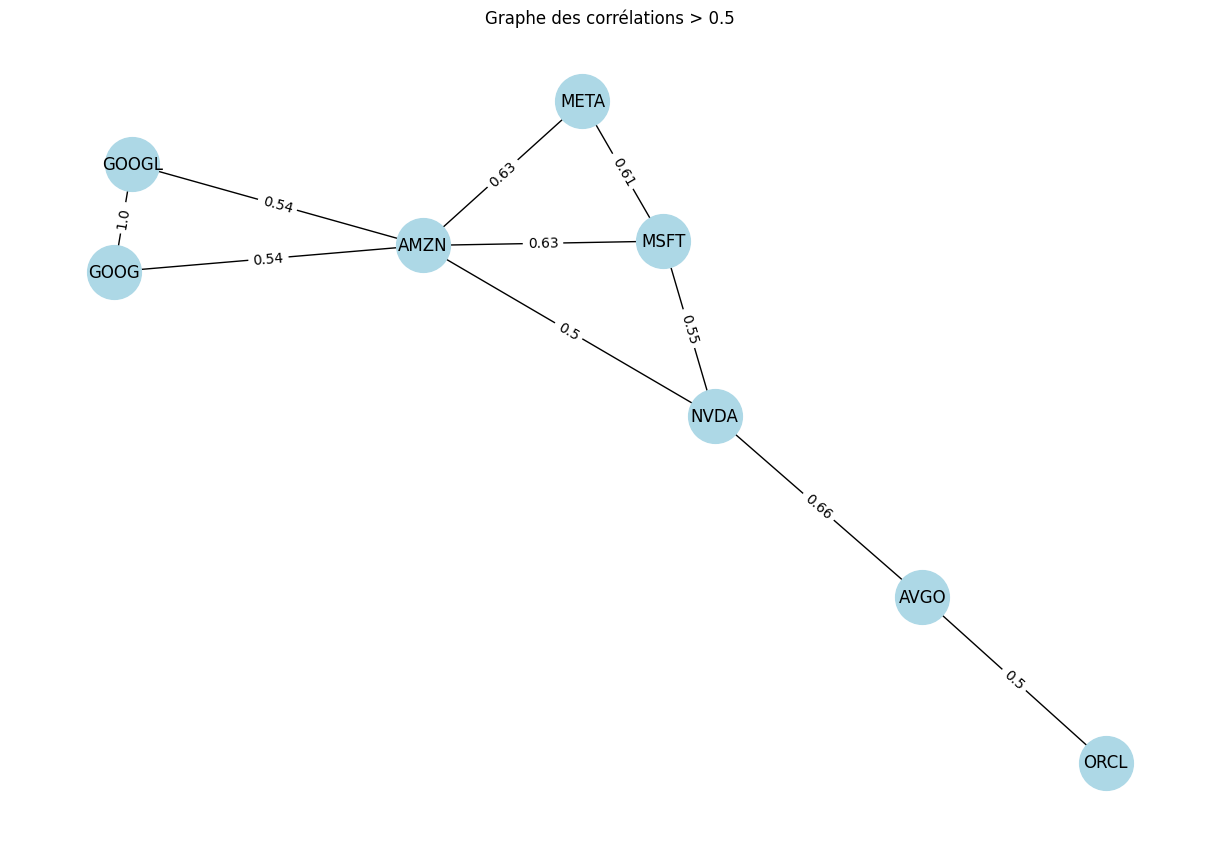

In [20]:
seuil_corr = 0.5
corr = rend_log.corr()

G = nx.Graph()

for i in corr.columns:
    for j in corr.columns:
        if i < j and corr.loc[i, j] > seuil_corr:
            G.add_edge(i, j, weight=round(corr.loc[i, j], 2))

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=1500)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
plt.title(f"Graphe des corrélations > {seuil_corr}")
plt.show()

**Justification du seuil et interprétation :**
- Le **seuil de 0.5** a été choisi comme valeur arbitraire représentant une corrélation modérée à forte. En dessous de 0.5, la relation entre deux actions est trop faible pour être économiquement significative.
- Les actions reliées dans le graphe évoluent de façon similaire — elles appartiennent probablement au même secteur ou sont soumises aux mêmes facteurs macroéconomiques.
- Les actions isolées (sans arête) sont peu corrélées avec les autres et apportent donc plus de diversification au portefeuille.

## Question 9 - Minimum Spanning Tree

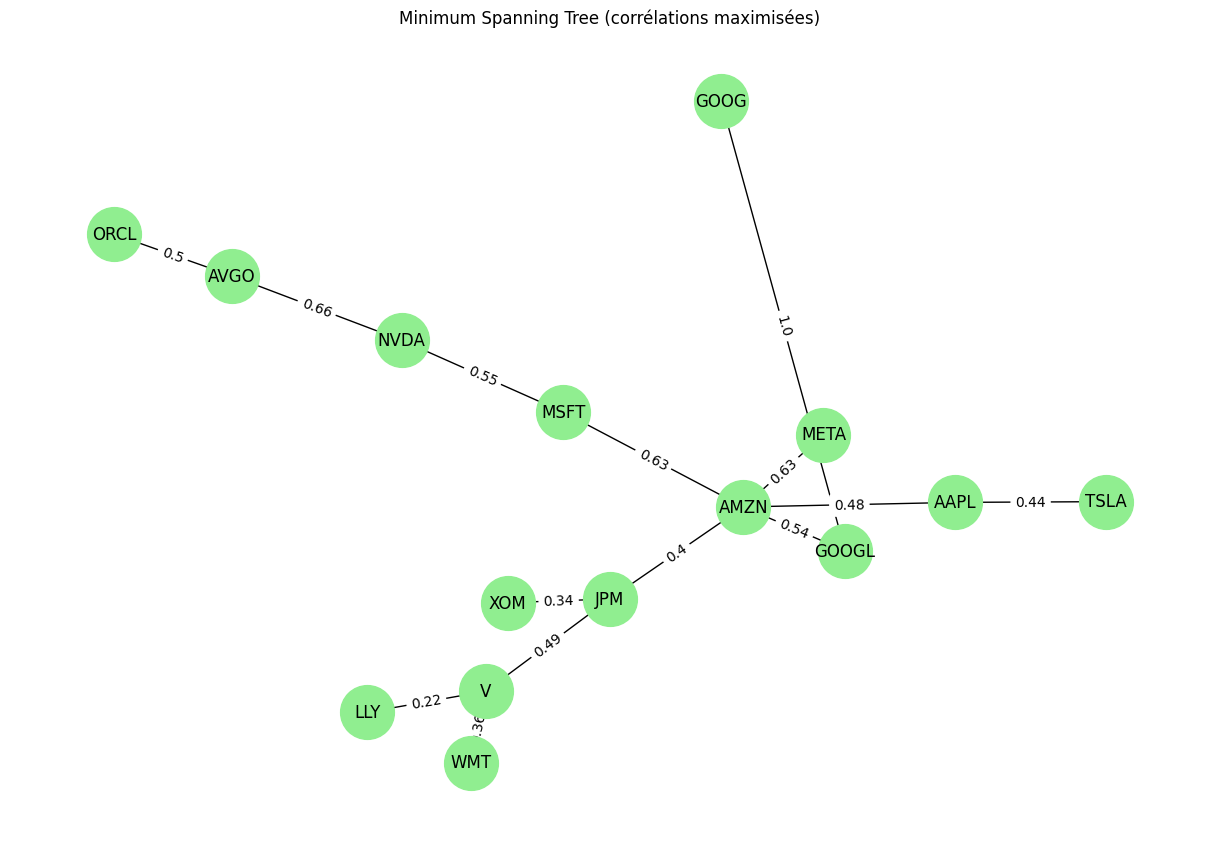

In [21]:
G2 = nx.Graph()

for i in corr.columns:
    for j in corr.columns:
        if i < j:
            G2.add_edge(i, j, weight=1 - corr.loc[i, j])

MST = nx.minimum_spanning_tree(G2)

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(MST, seed=42)
nx.draw(MST, pos, with_labels=True, node_color='lightgreen', node_size=1500)
labels = {(i, j): round(1 - d['weight'], 2) for i, j, d in MST.edges(data=True)}
nx.draw_networkx_edge_labels(MST, pos, edge_labels=labels)
plt.title("Minimum Spanning Tree (corrélations maximisées)")
plt.show()

**Justification et interprétation :**

- Les actions **centrales** dans le MST (avec beaucoup de connexions) sont les plus influentes du marché, elles jouent un rôle de "hub" et sont fortement corrélées avec beaucoup d'autres actions.
- Les actions **en périphérie** sont plus indépendantes et offrent une meilleure diversification dans un portefeuille.